In [8]:
# to implement and visualixe different ml model evaluation techniques usimg Confusion matrix heatmap ,
#roc curve ,precision recall curve ,learning curve ,feature importance plot,and residual plot

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    roc_curve,
    auc,
    precision_recall_curve
)

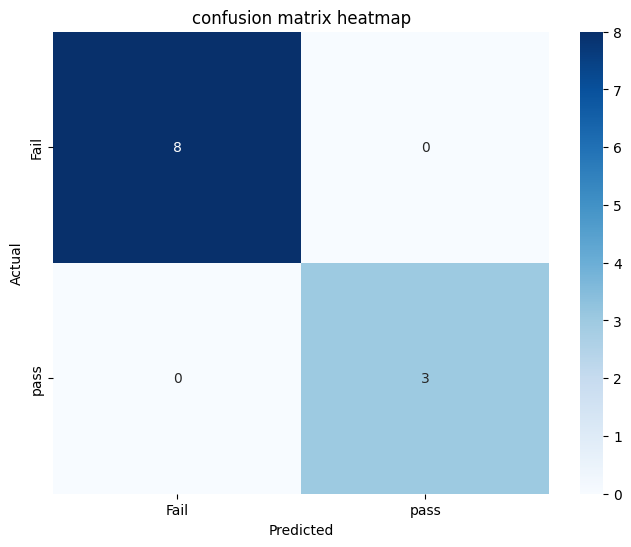

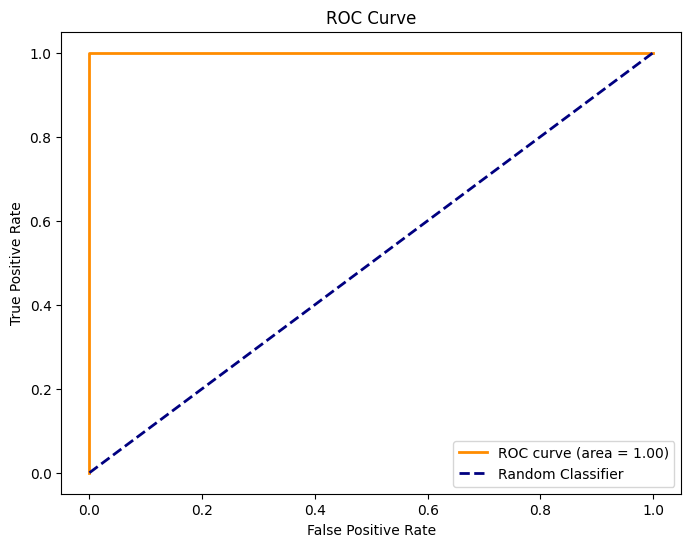

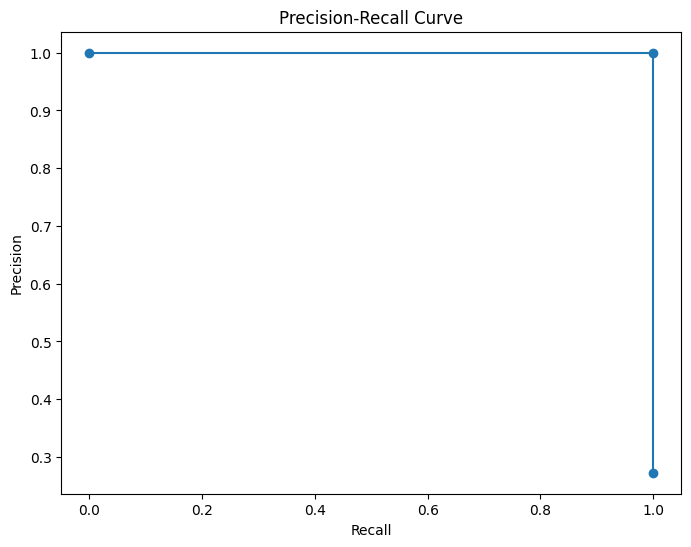

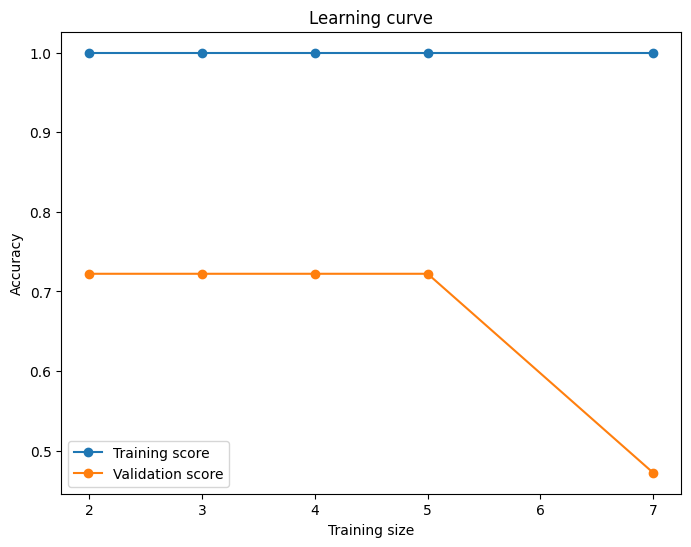

In [10]:
# part1: classification data
x_class = np.array([
    [2,55,50],
    [3,60,55],
    [4,65,60],
    [5,70,65],
    [6,70,65],
    [7,80,75],
    [8,85,80],
    [9,90,85],
    [3,58,52],
    [4,68,62],
    [6,78,72]


])

y_class = np.array([0,0,0,0,0,0,0,0,1,1,1])


# Train classification model
classifier = DecisionTreeClassifier()
classifier.fit(x_class, y_class)

# Make predictions
y_pred = classifier.predict(x_class)


# probability of class 1
y_prob = classifier.predict_proba(x_class)[:, 1]


#1 . confusion matrix heatmap
cm = confusion_matrix(y_class, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fail','pass'], yticklabels=['Fail','pass'])
plt.title('confusion matrix heatmap')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

#2 . Roc curve
fpr,tpr,thresholds = roc_curve(y_class,y_prob)
roc_auc = auc(fpr,tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,color='darkorange',lw=2,label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0,1],[0,1],linestyle='--',color='navy',lw=2,label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.show()

# 3. PRESICION RECALL CURVE
precision,recall,thresholds = precision_recall_curve(y_class,y_prob)
plt.figure(figsize=(8,6))
plt.plot(recall,precision,marker ='o')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

# learning curve
train_sizes,train_scores,test_scores = learning_curve(classifier,x_class,y_class,cv=3,train_sizes= np.linspace(0.4,1.0,5),
                                                      scoring='accuracy')
train_mean = train_scores.mean(axis=1)
validation_mean = test_scores.mean(axis=1)
plt.figure(figsize=(8,6))
plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training score')
plt.plot(
    train_sizes,
    validation_mean,
    marker='o',
    label='Validation score')
plt.xlabel('Training size')
plt.ylabel('Accuracy')
plt.title('Learning curve')
plt.legend()
plt.show()

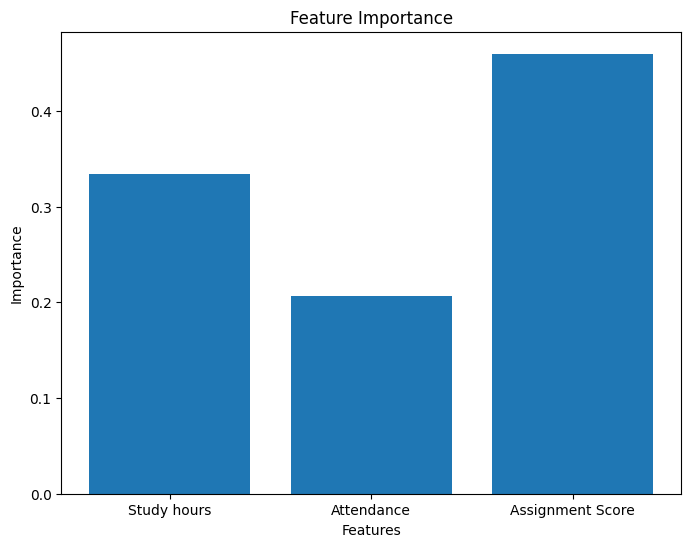

In [7]:
# feature importance plot
feature_names = [
    "Study hours",
    "Attendance",
    "Assignment Score"
]
importances = classifier.feature_importances_
plt.figure(figsize=(8,6))
plt.bar(feature_names,importances)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.show()


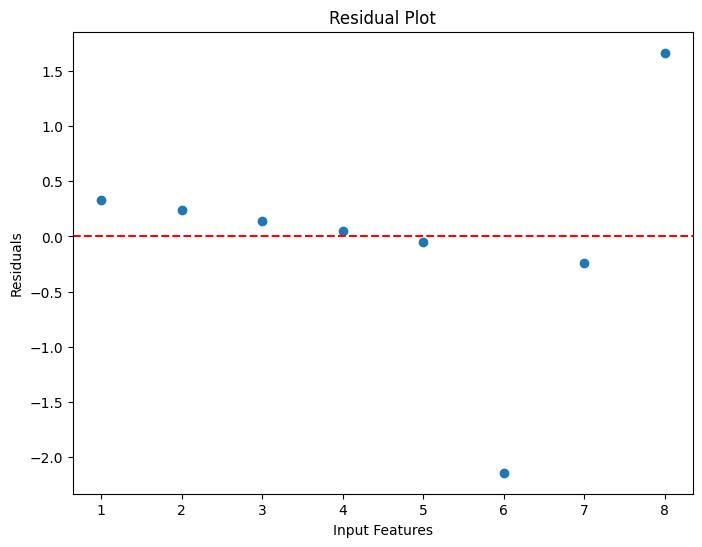

In [12]:
# part 2 : regression data
x_reg = np.array([
    [1],[2],[3],[4],[5],[6],[7],[8]
])
# actual output : Marks
y_reg = np.array([35,40,45,50,55,58,65,72])


# train reg model
regressor = LinearRegression()
regressor.fit(x_reg,y_reg)

# make predictions
y_pred = regressor.predict(x_reg)

# residual plot
residuals = y_reg - y_pred
plt.figure(figsize=(8,6))
plt.scatter(x_reg,residuals)
plt.axhline(y=0,color='r',linestyle='--')
plt.xlabel("Input Features")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()